# A local learning rule for skew-symmetric connectivity (Fig. 8)

Reproduces Fig. 8 (Appendix J.4): a local rule driven by time-lagged antisymmetric
correlations,

$$\Delta W_{ij} = \eta\big(r_i(t)r_j(t+\tau) - r_j(t)r_i(t+\tau)\big) - \alpha W_{ij},$$

drives $W$ toward the skew-symmetry of Sec. 2.3. Splitting $W$ into $S = W + W^\top$ and
$A = W - W^\top$ separates the dynamics. The Hebbian term is antisymmetric, so it contributes
nothing to $S$ and $S(t) = (1-\alpha)^t S(0)$ for any input. $A$ is driven by the correlations
and held by the decay, with the steady state $A^* = \tfrac{2\eta}{\alpha}\langle H\rangle_t$.

Fig. 8 drives the rule with independent rates, as in the appendix. For such rates
$\langle H\rangle$ falls as $1/\sqrt{T}$, so the persisting skew-symmetric part reflects the
fluctuations of the correlations rather than a steady state. With rates transported by a
generator, $r(t+1) = e^{\delta t\,\Omega}r(t)$, the average converges and the learned $A$
matches $A^*$. The appendix reports both correlations, and the cells after the figure
reproduce them. The last cell shows the limitation the appendix states: the rule gives a
skew-symmetric matrix, not a commuting pair.

The rates and the initial weights of the printed figure were drawn without a seed, so the lines
differ from the print. `SEED` fixes every draw here.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from expmap.plasticity import (
    antisymmetric_correlation,
    learn_connectivity,
    steady_state_antisymmetric,
    transported_activity,
)

# Fig. 8: a 32 x 32 weight matrix, alpha = 0.001, eta = 0.01, 5000 iterations (App. J.4).
N = 32
ETA = 0.01
ALPHA = 0.001
LAG = 1
T = 5000
SEED = 0
DRAW_EVERY = 50  # iterations between drawn points of the skew-symmetric panel; 1 draws every step as the print does, at 50 MB for the svg

rng = np.random.default_rng(SEED)

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

In [2]:
noise_rates = rng.standard_normal((T + LAG, N)) * 0.5
W0 = rng.standard_normal((N, N)) * 0.1

W_noise, history = learn_connectivity(noise_rates, eta=ETA, alpha=ALPHA, lag=LAG, W0=W0, record_weights=True)
weights = history["weights"]

# S(t) = (1 - alpha)^t S(0) is an identity, so it holds to machine precision.
steps = np.arange(T)
closed_form = (1 - ALPHA) ** steps * np.sqrt(np.mean((W0 + W0.T) ** 2))
print(f"max |S(t) - (1 - alpha)^t S(0)| = {np.max(np.abs(history['symmetric_rms'] - closed_form)):.1e}")
print(f"symmetric RMS {history['symmetric_rms'][0]:.4f} -> {history['symmetric_rms'][-1]:.1e}")
print(f"antisymmetric RMS {history['antisymmetric_rms'][0]:.4f} -> {history['antisymmetric_rms'][-1]:.4f}")

max |S(t) - (1 - alpha)^t S(0)| = 6.9e-17
symmetric RMS 0.1444 -> 9.7e-04
antisymmetric RMS 0.1458 -> 0.1554


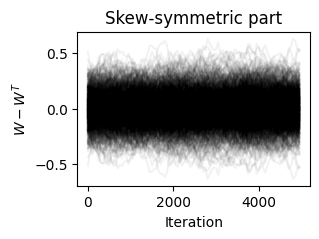

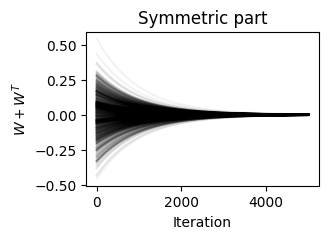

In [3]:
# Fig. 8: every entry of the skew-symmetric and the symmetric part over the iterations.
for part, label, title, name, every in [
    (weights - weights.transpose(0, 2, 1), r"$W - W^T$", "Skew-symmetric part", "learning_rule_skew_symmetric", DRAW_EVERY),
    (weights + weights.transpose(0, 2, 1), r"$W + W^T$", "Symmetric part", "learning_rule_symmetric", 1),
]:
    plt.figure(figsize=(3, 2))
    plt.plot(steps[::every], part[::every].reshape(-1, N * N), "-k", alpha=0.05)
    plt.ylabel(label)
    plt.xlabel("Iteration")
    plt.title(title)
    plt.savefig(FIGURE_DIR / f"{name}.svg", dpi=300, bbox_inches="tight")
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

## The steady state

$\langle H\rangle$ sets the steady state. For independent rates it falls as $1/\sqrt{T}$, and
for rates transported by a generator it converges to a limit. The learned $A$ is then compared
with $A^*$ for both inputs, which gives the two correlations reported in Appendix J.4.

independent rates : 0.0014 (T=1000) -> 0.0003 (T=16000)
transported       : 0.0010 (T=1000) -> 0.0009 (T=16000)


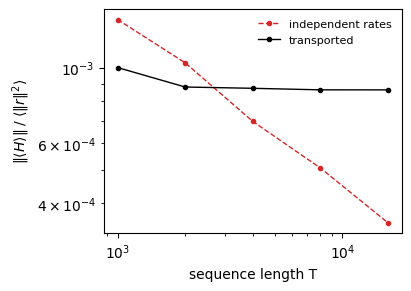

In [4]:
A_true = rng.standard_normal((N, N))
OMEGA = (A_true - A_true.T) / np.sqrt(N)  # the generator carrying the transported activity

lengths = [1000, 2000, 4000, 8000, 16000]
correlation_scale = {"independent rates": [], "transported": []}

for length in lengths:
    noise = rng.standard_normal((length + LAG, N)) * 0.5
    structured = transported_activity(OMEGA, n_steps=length + LAG, seed=SEED)
    for label, rates in [("independent rates", noise), ("transported", structured)]:
        # <H> scales with the squared activity, and the two inputs have different amplitudes.
        magnitude = np.sqrt(np.mean(antisymmetric_correlation(rates, LAG) ** 2))
        correlation_scale[label].append(magnitude / np.mean(np.sum(rates**2, axis=1)))

fig, ax = plt.subplots(figsize=(4, 2.8), layout="constrained")
for label, style in [("independent rates", "C3--o"), ("transported", "k-o")]:
    ax.loglog(lengths, correlation_scale[label], style, markersize=3, linewidth=1, label=label)
ax.set_xlabel("sequence length T")
ax.set_ylabel(r"$\|\langle H \rangle\| \;/\; \langle \|r\|^2 \rangle$")
ax.legend(fontsize=8, frameon=False)

for label, values in correlation_scale.items():
    print(f"{label:18s}: {values[0]:.4f} (T={lengths[0]}) -> {values[-1]:.4f} (T={lengths[-1]})")

corr(A, A*), transported       = 0.96
corr(A, A*), independent rates = 0.66


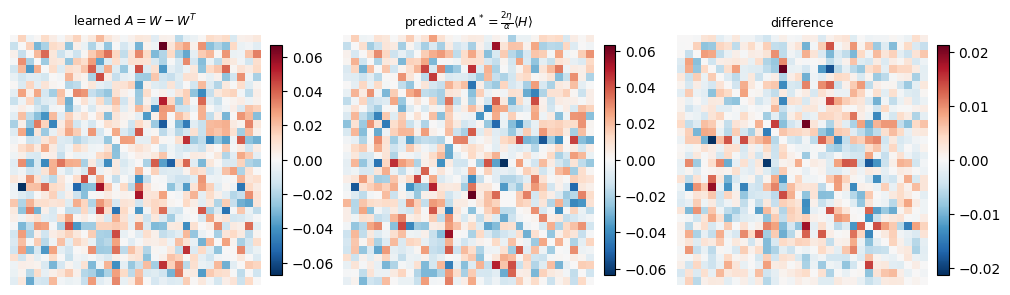

In [5]:
structured = transported_activity(OMEGA, n_steps=T + LAG, seed=SEED)
W_structured, _ = learn_connectivity(structured, eta=ETA, alpha=ALPHA, lag=LAG, seed=SEED)

A_learned = W_structured - W_structured.T
A_predicted = steady_state_antisymmetric(structured, eta=ETA, alpha=ALPHA, lag=LAG)
A_noise = W_noise - W_noise.T
A_noise_predicted = steady_state_antisymmetric(noise_rates, eta=ETA, alpha=ALPHA, lag=LAG)

print(f"corr(A, A*), transported       = {np.corrcoef(A_learned.ravel(), A_predicted.ravel())[0, 1]:.2f}")
print(f"corr(A, A*), independent rates = {np.corrcoef(A_noise.ravel(), A_noise_predicted.ravel())[0, 1]:.2f}")

fig, axs = plt.subplots(1, 3, figsize=(10, 3), layout="constrained")
for ax, matrix, title in [
    (axs[0], A_learned, r"learned $A = W - W^T$"),
    (axs[1], A_predicted, r"predicted $A^* = \frac{2\eta}{\alpha}\langle H \rangle$"),
    (axs[2], A_learned - A_predicted, "difference"),
]:
    im = ax.imshow(matrix, cmap="RdBu_r")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

## The limitation

The rule gives a skew-symmetric matrix, and nothing makes two such matrices commute. Path
integration needs a commuting pair (Sec. 2.2).

In [6]:
second = rng.standard_normal((N, N))
OMEGA_2 = (second - second.T) / np.sqrt(N)
W_second, _ = learn_connectivity(
    transported_activity(OMEGA_2, n_steps=T + LAG, seed=SEED + 1), eta=ETA, alpha=ALPHA, lag=LAG, seed=SEED + 1
)
A, B = A_learned, W_second - W_second.T


def rms(x):
    return np.sqrt(np.mean(x**2))


print(f"skew-symmetry of A and B: {rms(A + A.T) / rms(A):.1e}, {rms(B + B.T) / rms(B):.1e}")
print(f"||[A, B]|| = {rms(A @ B - B @ A):.4f} against ||A|| ||B|| = {rms(A) * rms(B):.4f}")

skew-symmetry of A and B: 0.0e+00, 0.0e+00
||[A, B]|| = 0.0036 against ||A|| ||B|| = 0.0004
